In [1]:
# importing basic libraries for bayesian modeling and plots
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import BayesianRidge

In [2]:
# loading the admissions dataset
df = pd.read_csv('Admission_Prediction.csv')
print(df.head(3))

   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0           1        337          118                  4  4.5  4.5  9.65   
1           2        324          107                  4  4.0  4.5  8.87   
2           3        316          104                  3  3.0  3.5  8.00   

   Research  Chance of Admit  Year  \
0         1             0.92  2022   
1         1             0.76  2022   
2         1             0.72  2022   

                              University_Name region  
0    Indian Institute of Technology Kharagpur   East  
1  National Institute of Technology Karnataka  South  
2                          Gujarat University   West  


In [3]:
# selecting predictor features and target column
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Chance of Admit']

# splitting dataset into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('train size:', len(X_train))
print('test size:', len(X_test))

train size: 800
test size: 200


In [4]:
# fitting the bayesian linear regression model
# bayesian ridge uses prior knowledge to regularize feature weights
model = BayesianRidge()
model.fit(X_train, y_train)

# printing posterior mean weights
print('posterior feature weights:')
print(pd.Series(model.coef_, index=features).round(4))
print('\nintercept:', round(model.intercept_, 4))

posterior feature weights:
GRE Score            0.0015
TOEFL Score          0.0028
University Rating    0.0014
SOP                  0.0098
LOR                  0.0140
CGPA                 0.0481
Research             0.0357
dtype: float64

intercept: -0.5722


In [5]:
# drawing samples from the posterior distribution to measure uncertainty
mean_weights = model.coef_
cov_weights = model.sigma_

np.random.seed(42)
posterior_samples = np.random.multivariate_normal(mean_weights, cov_weights, size=1000)

# calculating 95% credible intervals for each feature
lower_ci = np.percentile(posterior_samples, 2.5, axis=0)
upper_ci = np.percentile(posterior_samples, 97.5, axis=0)

ci_df = pd.DataFrame({
    'feature': features,
    'mean': mean_weights.round(4),
    'lower 95%': lower_ci.round(4),
    'upper 95%': upper_ci.round(4)
})
print('feature weights with 95% credible intervals:')
print(ci_df)

feature weights with 95% credible intervals:
             feature    mean  lower 95%  upper 95%
0          GRE Score  0.0015     0.0007     0.0022
1        TOEFL Score  0.0028     0.0015     0.0041
2  University Rating  0.0014    -0.0060     0.0093
3                SOP  0.0098     0.0004     0.0198
4                LOR  0.0140     0.0033     0.0251
5               CGPA  0.0481     0.0313     0.0639
6           Research  0.0357     0.0185     0.0529


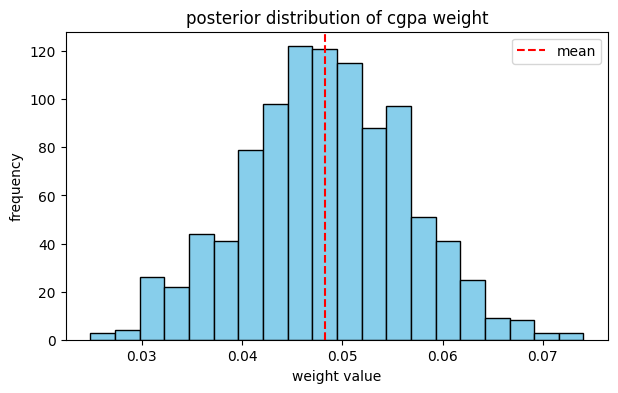

In [6]:
# simple histogram of posterior distribution for cgpa weight
cgpa_index = features.index('CGPA')
cgpa_samples = posterior_samples[:, cgpa_index]

plt.figure(figsize=(7, 4))
plt.hist(cgpa_samples, bins=20, color='skyblue', edgecolor='black')
plt.axvline(np.mean(cgpa_samples), color='red', linestyle='--', label='mean')
plt.title('posterior distribution of cgpa weight')
plt.xlabel('weight value')
plt.ylabel('frequency')
plt.legend()
plt.show()

rmse: 0.1188
average prediction uncertainty (std): 0.183


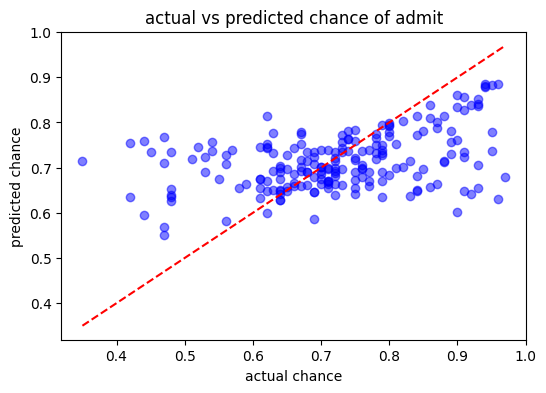

In [7]:
# predicting admission chances with uncertainty on test set
# return_std=True gives predictive standard deviation for each student
y_pred, y_std = model.predict(X_test, return_std=True)

# printing simple accuracy numbers
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
print('rmse:', round(rmse, 4))
print('average prediction uncertainty (std):', round(np.mean(y_std), 4))

# simple scatter plot of actual vs predicted admission chances
plt.figure(figsize=(6, 4))
plt.scatter(y_test, y_pred, color='blue', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.title('actual vs predicted chance of admit')
plt.xlabel('actual chance')
plt.ylabel('predicted chance')
plt.show()

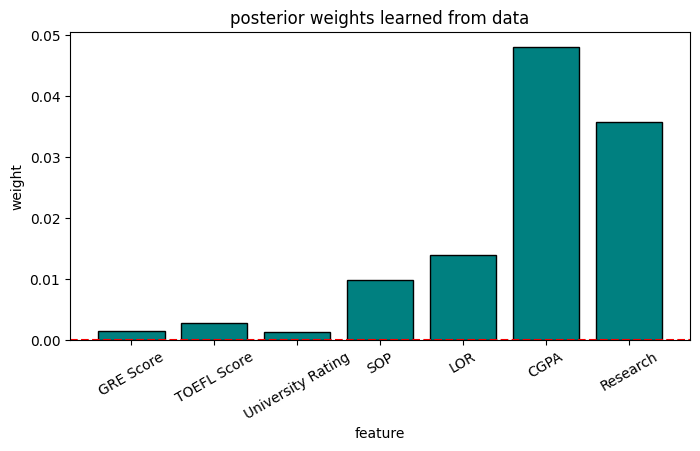

In [8]:
# comparing feature weights in a simple bar plot
# higher positive bars mean stronger impact on admission
plt.figure(figsize=(8, 4))
plt.bar(features, model.coef_, color='teal', edgecolor='black')
plt.axhline(0, color='red', linestyle='--')
plt.title('posterior weights learned from data')
plt.xlabel('feature')
plt.ylabel('weight')
plt.xticks(rotation=30)
plt.show()

probabilistic admission decisions (cutoff = 70%):
student a (high): expected chance = 0.85, probability of admission = 78.4%
student b (medium): expected chance = 0.71, probability of admission = 52.6%
student c (low): expected chance = 0.58, probability of admission = 24.2%


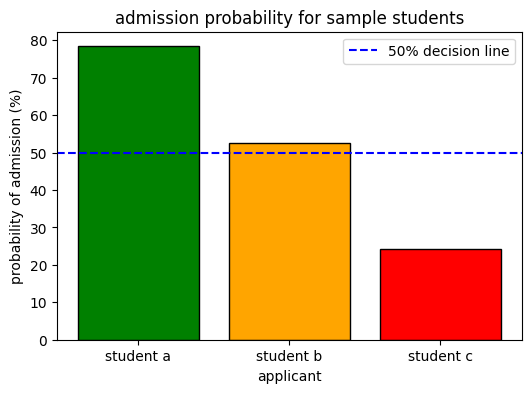

In [9]:
# probabilistic decision-making for three sample students
# calculating probability of getting admission chance >= 0.70
sample_students = pd.DataFrame([
    {'GRE Score': 330, 'TOEFL Score': 115, 'University Rating': 5, 'SOP': 4.5, 'LOR': 4.5, 'CGPA': 9.4, 'Research': 1},
    {'GRE Score': 315, 'TOEFL Score': 105, 'University Rating': 3, 'SOP': 3.5, 'LOR': 3.5, 'CGPA': 8.2, 'Research': 1},
    {'GRE Score': 300, 'TOEFL Score': 98,  'University Rating': 2, 'SOP': 2.5, 'LOR': 2.5, 'CGPA': 7.5, 'Research': 0}
], index=['student a (high)', 'student b (medium)', 'student c (low)'])

# getting predicted chance and uncertainty
pred_means, pred_stds = model.predict(sample_students, return_std=True)

# calculating admission probability above 70% cutoff
cutoff = 0.70
admit_probs = (1 - stats.norm.cdf(cutoff, loc=pred_means, scale=pred_stds)) * 100

print('probabilistic admission decisions (cutoff = 70%):')
for name, p_mean, p_prob in zip(sample_students.index, pred_means, admit_probs):
    print(f'{name}: expected chance = {p_mean:.2f}, probability of admission = {p_prob:.1f}%')

# simple bar plot showing admission probability for each student
student_names = ['student a', 'student b', 'student c']

plt.figure(figsize=(6, 4))
plt.bar(student_names, admit_probs, color=['green', 'orange', 'red'], edgecolor='black')
plt.axhline(50, color='blue', linestyle='--', label='50% decision line')
plt.title('admission probability for sample students')
plt.xlabel('applicant')
plt.ylabel('probability of admission (%)')
plt.legend()
plt.show()

In [10]:
# simple conclusion on bayesian analysis and probabilistic decisions
print('bayesian analysis summary:')
print('1. prior knowledge: bayesian regression starts with prior beliefs to prevent overfitting.')
print('2. uncertainty: each prediction gives an expected chance and an uncertainty value.')
print('3. credible intervals: 95% intervals show the likely range of each feature weight.')
print('4. decision making: probabilities allow universities to make clear threshold-based decisions.')

bayesian analysis summary:
1. prior knowledge: bayesian regression starts with prior beliefs to prevent overfitting.
2. uncertainty: each prediction gives an expected chance and an uncertainty value.
3. credible intervals: 95% intervals show the likely range of each feature weight.
4. decision making: probabilities allow universities to make clear threshold-based decisions.
